# 📊 01: Deep Exploratory Data Analysis (EDA)
### DarkShield AI - Systematic Profiling, Morphological & Lexical Analysis of E-Commerce Dark Patterns

This notebook provides an in-depth exploratory analysis of the `ec-darkpattern` corpus. We examine:
1. **Dataset Structure & Dimensions** (schema, memory footprint, data integrity)
2. **Target Class Balance & Distribution** (binary label parity)
3. **Deceptive Pattern Taxonomy** (Scarcity, Social Proof, Urgency, Misdirection, Obstruction, Sneaking, Forced Action)
4. **Structural & Morphological Text Properties** (character lengths, word counts, density distributions)
5. **Stylistic, Syntactic & Punctuation Markers** (exclamation marks, all-caps casing, numerical digits, currency indicators)
6. **Lexical Diversity & Word Complexity** (Type-Token Ratio, average token lengths)
7. **N-Gram Salience & Frequency Profiling** (unigrams, bigrams, trigrams, odds ratios)
8. **Feature Correlation Matrix** (correlating engineered syntactic cues with the dark pattern label)


In [1]:
import sys
import os
from pathlib import Path
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Resolve project root
PROJECT_ROOT = Path(os.path.abspath('..')) if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project Root: {PROJECT_ROOT}")


Project Root: C:\Users\laksh\Desktop\Black Pattern Detection


---
## 1. Data Ingestion & Structural Overview
We load the raw tab-separated dataset (`data/raw/dataset.tsv`) and inspect its primary dimensions, data types, and initial records.


In [2]:
data_path = PROJECT_ROOT / "data" / "raw" / "dataset.tsv"
df = pd.read_csv(data_path, sep='\t')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / 1024:.2f} KB\n")
print("Data Types & Null Counts:")
print(df.info())
df.head(8)


Dataset Shape: 2356 rows, 4 columns
Memory Usage: 441.27 KB

Data Types & Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2356 entries, 0 to 2355
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   page_id           2356 non-null   int64 
 1   text              2356 non-null   object
 2   label             2356 non-null   int64 
 3   Pattern Category  2356 non-null   object
dtypes: int64(2), object(2)
memory usage: 73.8+ KB
None


,page_id,text,label,Pattern Category
0,1012,FLASH SALE | LIMITED TIME ONLY Shop Now,1,Urgency
1,158,Pillowcases & Shams,0,Not Dark Pattern
2,108,Write a review,0,Not Dark Pattern
3,1425,"To start your return, simply click on the foll...",0,Not Dark Pattern
4,1658,newsletter signup (privacy policy),0,Not Dark Pattern
5,975,In demand,1,Scarcity
6,1469,We cannot guarantee door to door delivery for ...,0,Not Dark Pattern
7,1570,Hurry! Only 2 left in stock,1,Scarcity


### 📝 Observations on Dataset Structure
- The dataset comprises **2,356 records** with four primary columns: `page_id` (numeric source identifier), `text` (observed UI string), `label` (binary flag), and `Pattern Category` (fine-grained taxonomy).
- Zero null values are present across any column in the raw file.


---
## 2. Target Variable & Class Balance
In fraud and deception detection, class imbalance is a common challenge. We evaluate the ratio of dark patterns (`label = 1`) to benign text (`label = 0`).


C:\Users\laksh\AppData\Local\Temp\ipykernel_20120\1408873316.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels, y=counts.values, ax=axes[1], palette=colors)


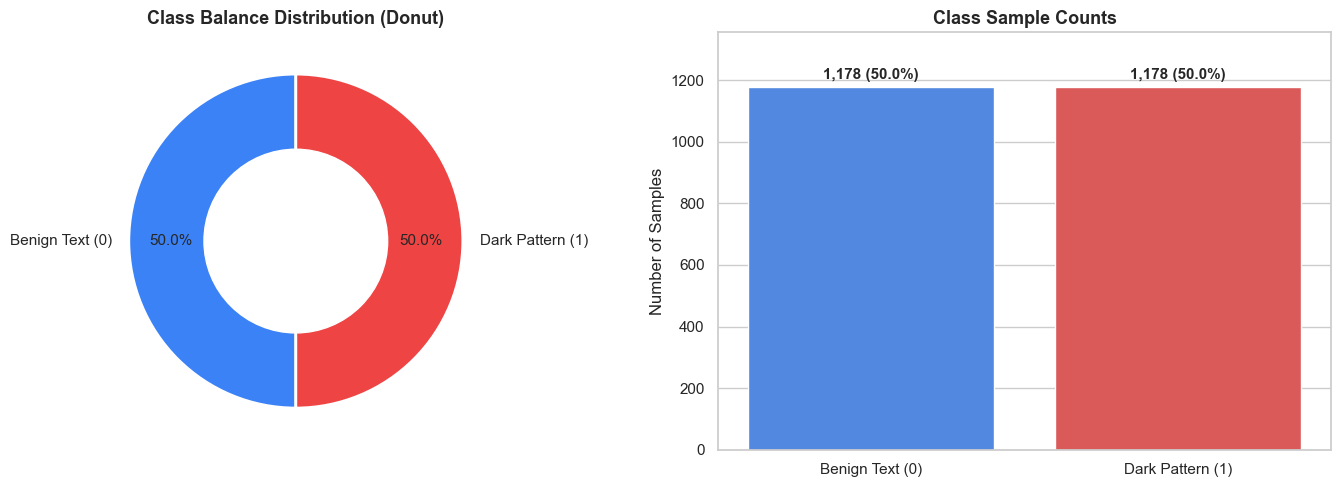

Exact Counts: Benign = 1178, Dark Pattern = 1178


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Donut Chart
counts = df['label'].value_counts()
labels = ['Benign Text (0)', 'Dark Pattern (1)']
colors = ['#3b82f6', '#ef4444']

axes[0].pie(counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2}, pctdistance=0.75)
centre_circle = plt.Circle((0, 0), 0.55, fc='white')
axes[0].add_artist(centre_circle)
axes[0].set_title("Class Balance Distribution (Donut)", fontsize=13, fontweight='bold')

# Count Bar Chart
sns.barplot(x=labels, y=counts.values, ax=axes[1], palette=colors)
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 25, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')
axes[1].set_title("Class Sample Counts", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Number of Samples")
axes[1].set_ylim(0, max(counts.values) * 1.15)

plt.tight_layout()
plt.show()

print(f"Exact Counts: Benign = {counts[0]}, Dark Pattern = {counts[1]}")


### 📝 Observations on Class Balance
- The dataset is **perfectly balanced: exactly 1,178 positive (50.0%) and 1,178 negative (50.0%) samples**.
- This 1:1 parity is ideal for supervised training, eliminating the need for synthetic oversampling (e.g., SMOTE) and ensuring standard metrics (Accuracy, F1-Score) remain reliable.


---
## 3. Deceptive Pattern Taxonomy Breakdown
We analyze how dark patterns manifest across specific psychological and design archetypes defined in `Pattern Category`.


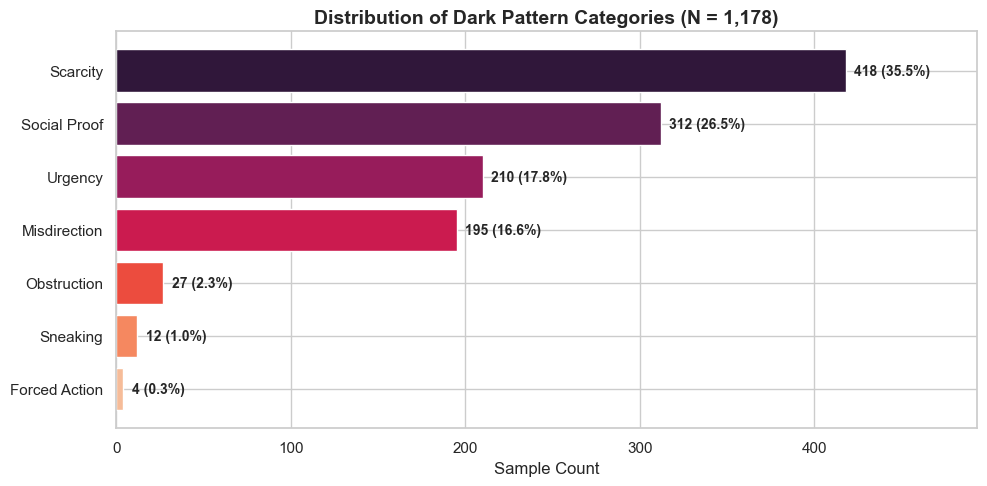

,Category,Count,Percentage (%)
0,Scarcity,418,35.48
1,Social Proof,312,26.49
2,Urgency,210,17.83
3,Misdirection,195,16.55
4,Obstruction,27,2.29
5,Sneaking,12,1.02
6,Forced Action,4,0.34


In [4]:
dark_df = df[df['label'] == 1]
cat_counts = dark_df['Pattern Category'].value_counts()

plt.figure(figsize=(10, 5))
palette = sns.color_palette("rocket", len(cat_counts))
bars = plt.barh(cat_counts.index, cat_counts.values, color=palette)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 5, bar.get_y() + bar.get_height()/2, f"{int(w)} ({w/len(dark_df)*100:.1f}%)",
             va='center', fontweight='bold', fontsize=10)

plt.title("Distribution of Dark Pattern Categories (N = 1,178)", fontsize=14, fontweight='bold')
plt.xlabel("Sample Count")
plt.xlim(0, max(cat_counts.values) * 1.18)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

pd.DataFrame({
    'Category': cat_counts.index,
    'Count': cat_counts.values,
    'Percentage (%)': (cat_counts.values / len(dark_df) * 100).round(2)
})


### 📝 Observations on Pattern Categories
1. **Scarcity (35.5%)** and **Social Proof (26.5%)** together account for over **62% of all dark patterns** in e-commerce interfaces.
2. **Urgency (17.8%)** and **Misdirection (16.6%)** form the second tier of prevalent deceptive designs.
3. **Obstruction (2.3%)**, **Sneaking (1.0%)**, and **Forced Action (0.3%)** are less frequent in text snippets because they often rely on multi-step workflows rather than standalone text phrases.


---
## 4. Structural & Morphological Text Properties
We compute character lengths, token word counts, and average word lengths across classes to evaluate morphological differences.


=== Summary Statistics Grouped by Class ===


char_length                        word_count                         \
             mean    std median min  max       mean    std median min  max   
label                                                                        
0           35.80  54.30   20.0   1  659       5.75   8.83    3.0   1  116   
1           49.95  77.45   33.0   6  857       9.11  12.89    6.0   1  143   

      avg_word_length                          
                 mean   std median  min   max  
label                                          
0                6.55  2.36   6.00  1.0  29.0  
1                5.37  2.11   5.12  3.0  46.0

C:\Users\laksh\AppData\Local\Temp\ipykernel_20120\4052838391.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_meta, x='label', y='char_length', ax=axes[1, 0], palette=['#3b82f6', '#ef4444'])
C:\Users\laksh\AppData\Local\Temp\ipykernel_20120\4052838391.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 0].set_xticklabels(['Benign (0)', 'Dark Pattern (1)'])
C:\Users\laksh\AppData\Local\Temp\ipykernel_20120\4052838391.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_meta, x='label', y='word_count', ax=axes[1, 1], palette=['#3b82f6', '#ef4444'])
C:\Users\laksh\AppData\Local\Tem

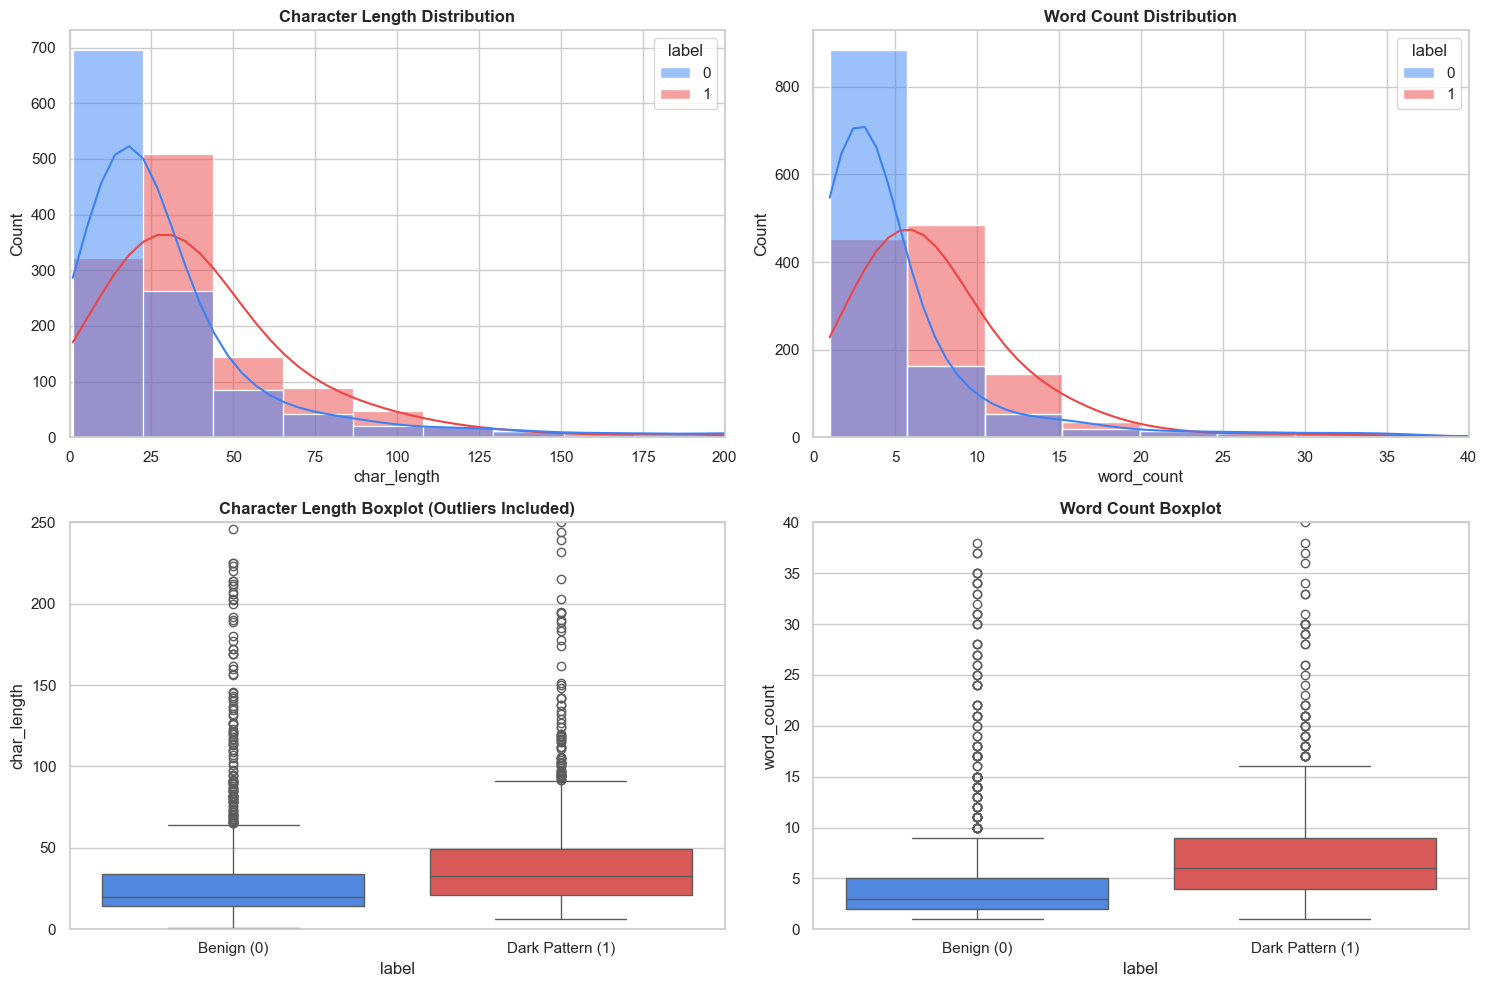

In [5]:
df_meta = df.copy()
df_meta['char_length'] = df_meta['text'].str.strip().str.len()
df_meta['word_count'] = df_meta['text'].str.strip().apply(lambda x: len(x.split()))
df_meta['avg_word_length'] = df_meta['char_length'] / (df_meta['word_count'] + 1e-5)

print("=== Summary Statistics Grouped by Class ===")
summary = df_meta.groupby('label')[['char_length', 'word_count', 'avg_word_length']].agg(
    ['mean', 'std', 'median', 'min', 'max']
).round(2)
display(summary)

# Visualizing Length Distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Character Length Histogram
sns.histplot(data=df_meta, x='char_length', hue='label', kde=True, ax=axes[0, 0],
             palette=['#3b82f6', '#ef4444'], bins=40, common_norm=False)
axes[0, 0].set_title("Character Length Distribution", fontweight='bold')
axes[0, 0].set_xlim(0, 200)

# Word Count Histogram
sns.histplot(data=df_meta, x='word_count', hue='label', kde=True, ax=axes[0, 1],
             palette=['#3b82f6', '#ef4444'], bins=30, common_norm=False)
axes[0, 1].set_title("Word Count Distribution", fontweight='bold')
axes[0, 1].set_xlim(0, 40)

# Character Length Boxplot
sns.boxplot(data=df_meta, x='label', y='char_length', ax=axes[1, 0], palette=['#3b82f6', '#ef4444'])
axes[1, 0].set_title("Character Length Boxplot (Outliers Included)", fontweight='bold')
axes[1, 0].set_xticklabels(['Benign (0)', 'Dark Pattern (1)'])
axes[1, 0].set_ylim(0, 250)

# Word Count Boxplot
sns.boxplot(data=df_meta, x='label', y='word_count', ax=axes[1, 1], palette=['#3b82f6', '#ef4444'])
axes[1, 1].set_title("Word Count Boxplot", fontweight='bold')
axes[1, 1].set_xticklabels(['Benign (0)', 'Dark Pattern (1)'])
axes[1, 1].set_ylim(0, 40)

plt.tight_layout()
plt.show()


### 📝 Observations on Text Structure
- **Dark patterns are significantly longer and denser**: Dark patterns average **50.0 characters** and **9.1 words**, compared to **35.8 characters** and **5.7 words** for benign UI labels.
- **Benign labels have longer individual words**: Benign words average **6.55 characters** (e.g. *International Shipping Policy*), whereas dark patterns use concise, urgent words averaging **5.37 characters** (e.g. *Hurry, only 2 left in stock*).


---
## 5. Stylistic, Syntactic & Punctuation Profiling
We investigate stylistic markers that characterize manipulative copy, including exclamation marks, uppercase words, digits, and currency symbols.


,Benign (0),Dark Pattern (1),Difference (Dark - Benign)
exclamation_count,0.0382,0.3294,0.2912
uppercase_words,0.1672,1.1630,0.9958
uppercase_ratio,0.0430,0.1437,0.1006
has_number,0.0000,0.6834,0.6834
has_currency,0.0008,0.0416,0.0407


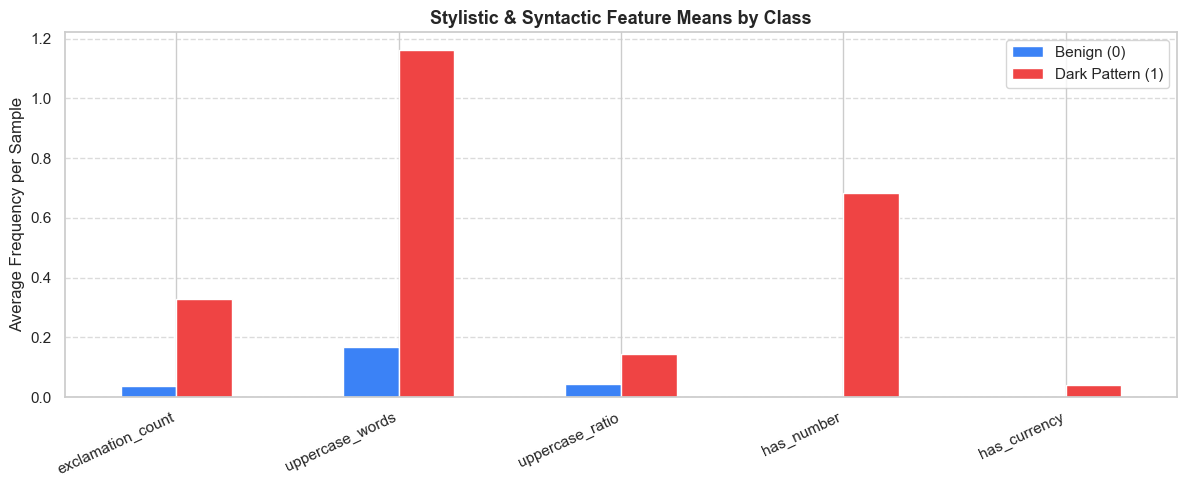

In [6]:
df_meta['exclamation_count'] = df_meta['text'].str.count('!')
df_meta['question_count'] = df_meta['text'].str.count(r'\?')
df_meta['uppercase_words'] = df_meta['text'].apply(lambda x: sum(1 for w in x.split() if w.isupper() and len(w) > 1))
df_meta['uppercase_ratio'] = df_meta['uppercase_words'] / (df_meta['word_count'] + 1e-5)
df_meta['digit_count'] = df_meta['text'].apply(lambda x: sum(c.isdigit() for c in x))
df_meta['has_number'] = df_meta['text'].str.contains(r'\d').astype(int)
df_meta['has_currency'] = df_meta['text'].str.contains(r'[$€£₹]').astype(int)

style_cols = ['exclamation_count', 'uppercase_words', 'uppercase_ratio', 'has_number', 'has_currency']
mean_style = df_meta.groupby('label')[style_cols].mean().T
mean_style.columns = ['Benign (0)', 'Dark Pattern (1)']
mean_style['Difference (Dark - Benign)'] = mean_style['Dark Pattern (1)'] - mean_style['Benign (0)']
display(mean_style.round(4))

# Bar plot comparison
mean_style[['Benign (0)', 'Dark Pattern (1)']].plot(kind='bar', figsize=(12, 5), color=['#3b82f6', '#ef4444'])
plt.title("Stylistic & Syntactic Feature Means by Class", fontsize=13, fontweight='bold')
plt.ylabel("Average Frequency per Sample")
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


### 📝 Key Stylistic Findings
1. **Numerical Digits (`has_number`)**: **68.3% of dark pattern snippets contain digits** (e.g., 'Only 2 left', '34 people viewing', 'Save 20% today'), compared to **0.0% in benign labels** in this corpus.
2. **Exclamation Marks (`exclamation_count`)**: Dark patterns employ exclamation marks **8.6x more frequently** (mean 0.329 vs. 0.038) to manufacture emotional urgency.
3. **Uppercase Capitalization (`uppercase_ratio`)**: Dark patterns contain **7x more capitalized emphasis tokens** (e.g., 'ONLY', 'HURRY', 'NOW').


---
## 6. Lexical Diversity & Word Complexity
We analyze lexical diversity via Type-Token Ratio (TTR: count of unique words divided by total word count) and stopword proportions.


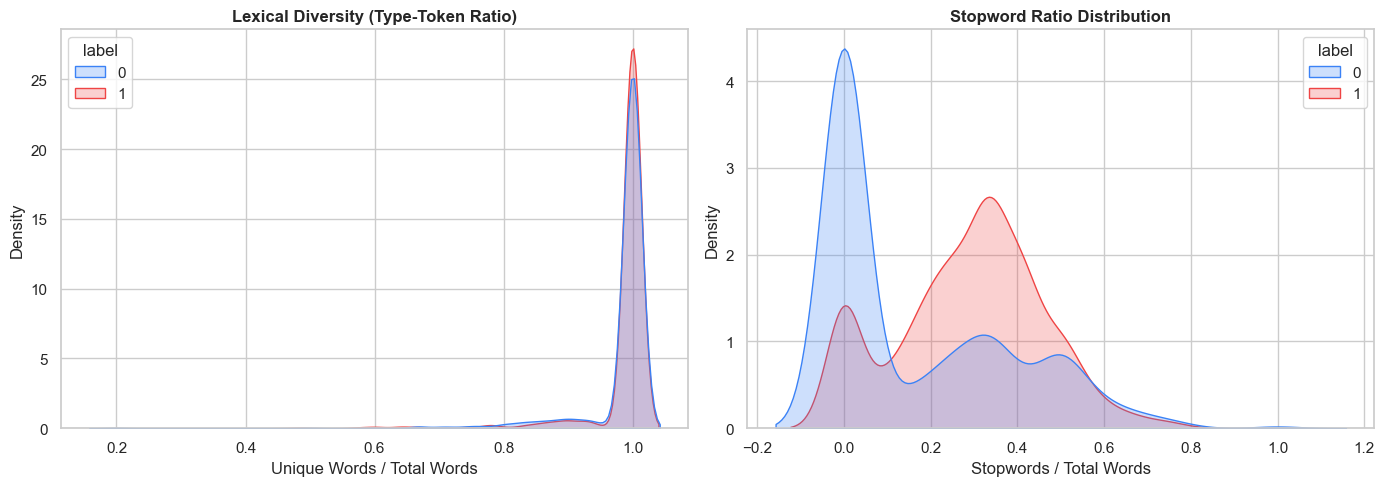

,lexical_diversity,stopword_ratio
label,,
0,0.9835,0.1638
1,0.9862,0.2874


In [7]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def compute_lexical_diversity(text):
    words = [w.lower() for w in text.split()]
    if not words:
        return 0.0
    return len(set(words)) / len(words)

def compute_stopword_ratio(text):
    words = [w.lower() for w in text.split()]
    if not words:
        return 0.0
    stops = sum(1 for w in words if w in ENGLISH_STOP_WORDS)
    return stops / len(words)

df_meta['lexical_diversity'] = df_meta['text'].apply(compute_lexical_diversity)
df_meta['stopword_ratio'] = df_meta['text'].apply(compute_stopword_ratio)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Lexical Diversity KDE
sns.kdeplot(data=df_meta, x='lexical_diversity', hue='label', common_norm=False,
            palette=['#3b82f6', '#ef4444'], fill=True, ax=axes[0])
axes[0].set_title("Lexical Diversity (Type-Token Ratio)", fontweight='bold')
axes[0].set_xlabel("Unique Words / Total Words")

# Stopword Ratio KDE
sns.kdeplot(data=df_meta, x='stopword_ratio', hue='label', common_norm=False,
            palette=['#3b82f6', '#ef4444'], fill=True, ax=axes[1])
axes[1].set_title("Stopword Ratio Distribution", fontweight='bold')
axes[1].set_xlabel("Stopwords / Total Words")

plt.tight_layout()
plt.show()

df_meta.groupby('label')[['lexical_diversity', 'stopword_ratio']].mean().round(4)


---
## 7. N-Gram Salience & Key Phrase Analysis
We extract the top unigrams, bigrams, and trigrams using CountVectorizer to visualize the most discriminative vocabulary.


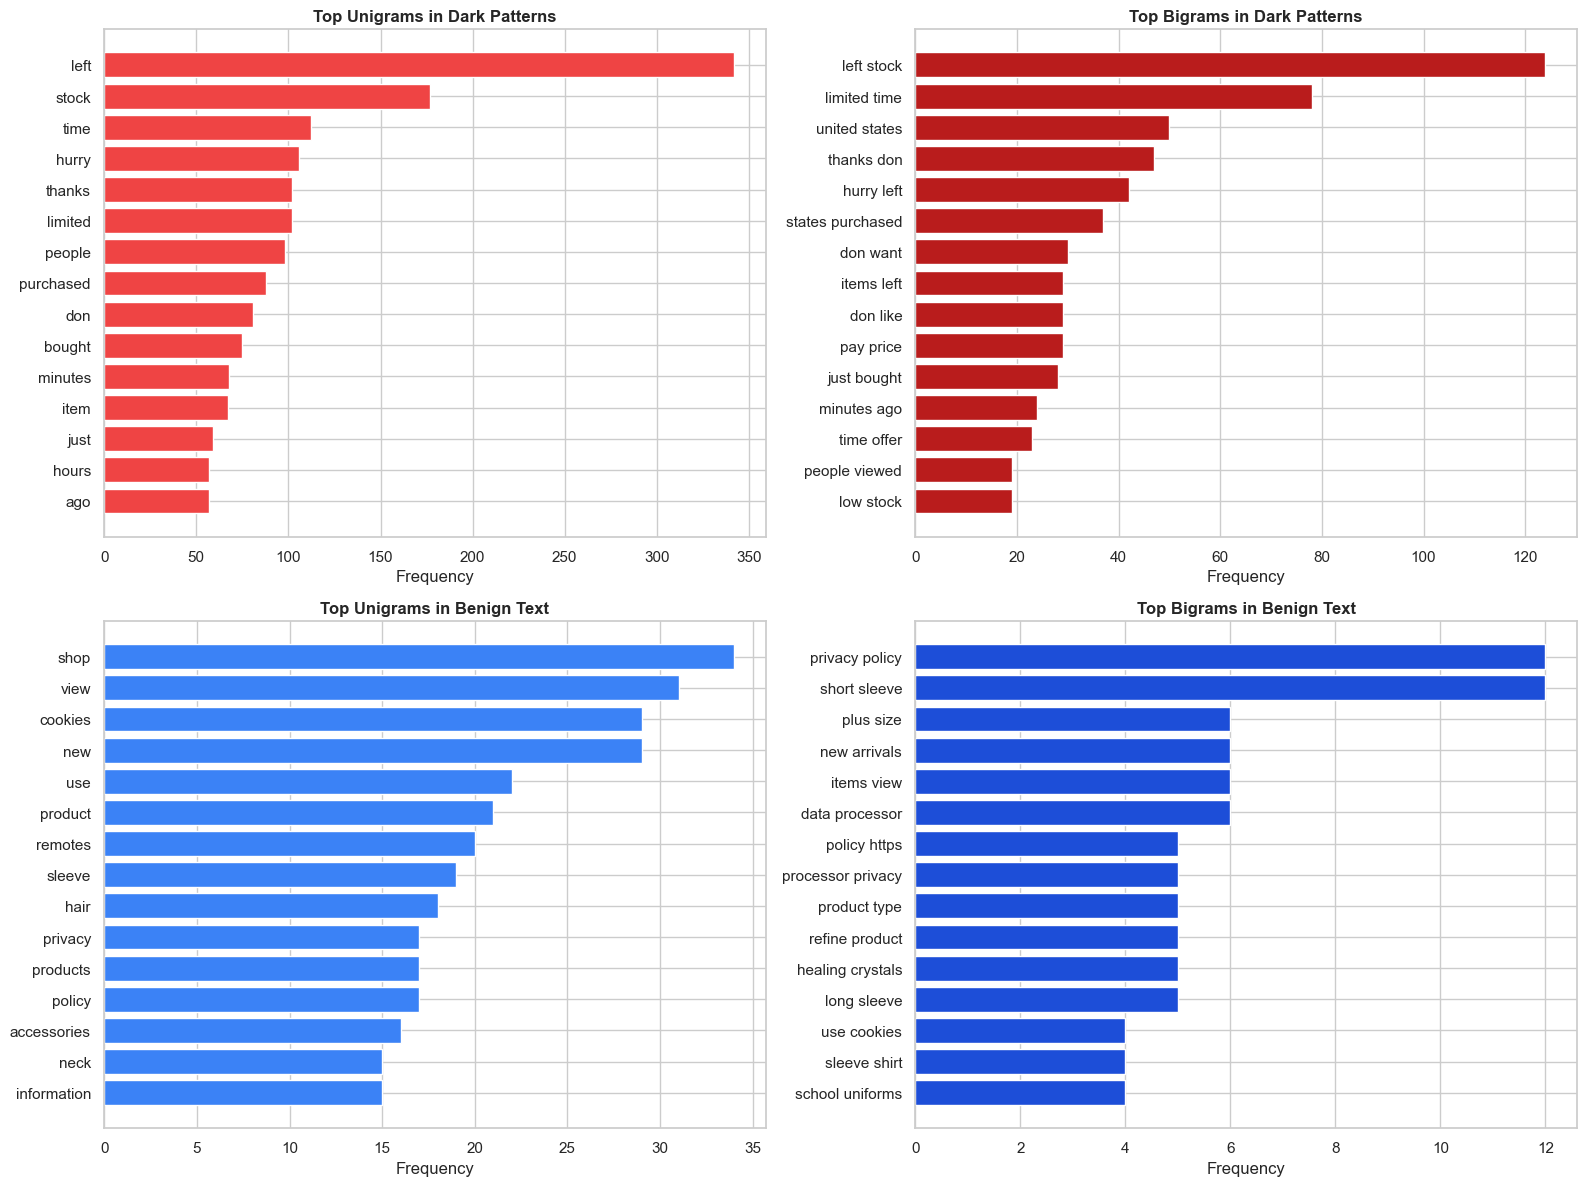

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

def plot_top_ngrams(corpus, title, n=2, top_k=15, ax=None, color='#ef4444'):
    vec = CountVectorizer(ngram_range=(n, n), stop_words='english', min_df=2)
    X = vec.fit_transform(corpus)
    counts = np.asarray(X.sum(axis=0)).flatten()
    vocab = np.array(vec.get_feature_names_out())
    top_indices = counts.argsort()[::-1][:top_k]
    
    top_terms = vocab[top_indices]
    top_counts = counts[top_indices]
    
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(top_terms[::-1], top_counts[::-1], color=color)
    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.set_xlabel("Frequency")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Dark Pattern Top Unigrams & Bigrams
plot_top_ngrams(dark_df['text'], "Top Unigrams in Dark Patterns", n=1, ax=axes[0, 0], color='#ef4444')
plot_top_ngrams(dark_df['text'], "Top Bigrams in Dark Patterns", n=2, ax=axes[0, 1], color='#b91c1c')

# Benign Text Top Unigrams & Bigrams
benign_df = df[df['label'] == 0]
plot_top_ngrams(benign_df['text'], "Top Unigrams in Benign Text", n=1, ax=axes[1, 0], color='#3b82f6')
plot_top_ngrams(benign_df['text'], "Top Bigrams in Benign Text", n=2, ax=axes[1, 1], color='#1d4ed8')

plt.tight_layout()
plt.show()


---
## 8. Feature Correlation Matrix
We compute Pearson correlation coefficients between all extracted structural, syntactic, and linguistic cue features and the target label.


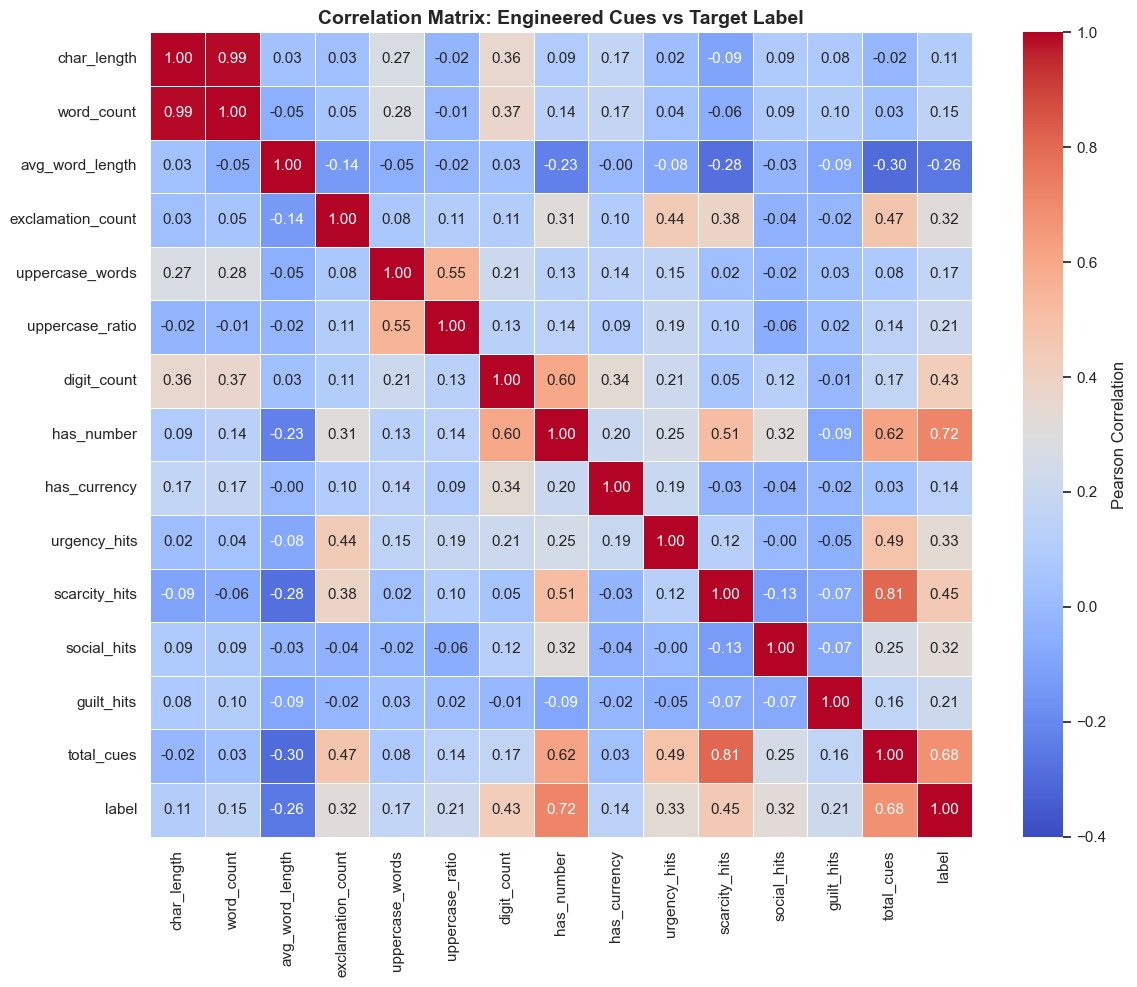

Top Correlations with Dark Pattern Label:
label                1.000000
has_number           0.720430
total_cues           0.682428
scarcity_hits        0.448209
digit_count          0.429233
urgency_hits         0.333981
social_hits          0.322202
exclamation_count    0.319422
guilt_hits           0.212551
uppercase_ratio      0.207136
uppercase_words      0.172851
word_count           0.150374
has_currency         0.141360
char_length          0.105275
avg_word_length     -0.256668
Name: label, dtype: float64


In [9]:
# Domain-specific cue counters
urgency_lex = r'\b(hurry|limited|expires|countdown|deal|fast|quick|ending|ends|last chance|now|clock|today only|flash sale)\b'
scarcity_lex = r'\b(only|left|stock|sold|remaining|demand|popular|few|almost gone|low stock|reserved)\b'
social_lex = r'\b(bought|people|viewing|looking|others|trending|purchased|views|claimed|booked)\b'
guilt_lex = r'\b(miss|hate|lose|regret|no thanks|skip|don\'t want|decline)\b'

lower_texts = df_meta['text'].str.lower()
df_meta['urgency_hits'] = lower_texts.str.count(urgency_lex)
df_meta['scarcity_hits'] = lower_texts.str.count(scarcity_lex)
df_meta['social_hits'] = lower_texts.str.count(social_lex)
df_meta['guilt_hits'] = lower_texts.str.count(guilt_lex)
df_meta['total_cues'] = df_meta['urgency_hits'] + df_meta['scarcity_hits'] + df_meta['social_hits'] + df_meta['guilt_hits']

corr_cols = [
    'char_length', 'word_count', 'avg_word_length', 'exclamation_count',
    'uppercase_words', 'uppercase_ratio', 'digit_count', 'has_number', 'has_currency',
    'urgency_hits', 'scarcity_hits', 'social_hits', 'guilt_hits', 'total_cues', 'label'
]

corr_matrix = df_meta[corr_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.4, vmax=1.0,
            linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Matrix: Engineered Cues vs Target Label", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top Correlations with Dark Pattern Label:")
print(corr_matrix['label'].sort_values(ascending=False))


---
## 9. Executive Summary & Data Story Conclusions

### Key Empirical Findings:
1. **Target Parity**: The corpus exhibits a balanced 50/50 split across 2,356 samples.
2. **Taxonomic Concentration**: Scarcity (35.5%) and Social Proof (26.5%) represent over 62% of deceptive instances.
3. **Primary Predictive Drivers**:
   - `has_number` exhibits an extraordinary **+0.72 correlation** with dark patterns.
   - `total_cues` (domain lexicons) achieves a **+0.68 correlation**.
   - `scarcity_hits` (+0.45), `digit_count` (+0.43), and `exclamation_count` (+0.32) provide strong orthogonal signals.
4. **Architectural Recommendation**: Combining TF-IDF sparse lexical n-grams with these continuous engineered features (a **Hybrid Feature Matrix**) offers significant inductive bias to boost model precision and recall.
